<a href="https://colab.research.google.com/github/fzh05/Decicion-Making/blob/main/Olah_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import io
import numpy as np
import pandas as pd
import requests

url = "https://raw.githubusercontent.com/fzh05/Decicion-Making/a14aaf9c84051516e68f4f8c3fbc512cf36b0300/POWER_Point_Daily_20250101_20251231_005d16S_105d11E_UTC.csv"

# 1. Unduh dan cari batas header secara dinamis (bukan skiprows=20)
resp = requests.get(url, timeout=60)
resp.raise_for_status()
lines = resp.text.splitlines()
header_end = next(i for i, l in enumerate(lines) if "-END HEADER-" in l)
df_raw = pd.read_csv(io.StringIO("\n".join(lines[header_end + 1:])))

# 2. Tanggal dari YEAR + DOY (lebih tahan salah)
df_raw["date"] = pd.to_datetime(df_raw["YEAR"].astype(str), format="%Y") \
                 + pd.to_timedelta(df_raw["DOY"] - 1, unit="D")

# 3. Pilih kolom + pastikan semuanya ada
kolom = ["date", "IMERG_PRECTOT", "PRECTOTCORR", "GWETTOP",
         "T2M_MAX", "T2M_MIN", "WS2M"]
hilang = [c for c in kolom if c not in df_raw.columns]
assert not hilang, f"Kolom tidak ditemukan: {hilang}"
df_raw = df_raw[kolom]

# 4. Audit singkat (bukan menampilkan 365 baris)
print("Shape         :", df_raw.shape)
print("Rentang tgl   :", df_raw.date.min().date(), "→", df_raw.date.max().date())
print("Jumlah -999   :\n", (df_raw.drop(columns="date") == -999).sum())
print("Duplikat tgl  :", df_raw.date.duplicated().sum())
df_raw.describe().T

Shape         : (365, 7)
Rentang tgl   : 2025-01-01 → 2025-12-31
Jumlah -999   :
 IMERG_PRECTOT    0
PRECTOTCORR      0
GWETTOP          0
T2M_MAX          0
T2M_MIN          0
WS2M             0
dtype: int64
Duplikat tgl  : 0


,count,mean,min,25%,50%,75%,max,std
date,365,2025-07-01 23:59:59.999999744,2025-01-01 00:00:00,2025-04-02 00:00:00,2025-07-02 00:00:00,2025-10-01 00:00:00,2025-12-31 00:00:00,NaN
IMERG_PRECTOT,365.0,8.563397,0.0,0.19,2.96,12.69,69.16,12.338202
PRECTOTCORR,365.0,6.773014,0.0,0.18,1.36,6.81,56.35,11.506079
GWETTOP,365.0,0.841205,0.67,0.8,0.85,0.89,0.96,0.063878
T2M_MAX,365.0,29.700849,25.71,29.02,29.78,30.47,32.53,1.10515
T2M_MIN,365.0,23.303616,21.39,22.95,23.37,23.73,25.06,0.639546
WS2M,365.0,0.755041,0.33,0.59,0.72,0.89,1.42,0.219583


In [2]:
print("NaN per kolom:\n", df_raw.isna().sum())

NaN per kolom:
 date             0
IMERG_PRECTOT    0
PRECTOTCORR      0
GWETTOP          0
T2M_MAX          0
T2M_MIN          0
WS2M             0
dtype: int64


File 2025 ini lengkap dan bebas missing value.

In [3]:
import os
import io
import requests
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_recall_fscore_support
)
import xgboost as xgb

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# URL Raw dari GitHub Public Anda
INPUT_URL = "https://raw.githubusercontent.com/fzh05/Decicion-Making/a14aaf9c84051516e68f4f8c3fbc512cf36b0300/POWER_Point_Daily_20250101_20251231_005d16S_105d11E_UTC.csv"
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================================================================
# 1. LOAD & CLEANING DATA (MEMBACA DARI URL GITHUB)
# =========================================================================
def load_power_data_from_url(url):
    """
    Mengunduh isi file dari URL GitHub dan mencari batas '-END HEADER-' secara dinamis.
    """
    response = requests.get(url)
    response.raise_for_status()
    lines = response.text.splitlines()

    # Cari indeks baris yang mengandung '-END HEADER-'
    header_end_idx = next(i for i, line in enumerate(lines) if "-END HEADER-" in line)
    data_start_idx = header_end_idx + 1

    # Membaca data CSV dari memori
    csv_data = "\n".join(lines[data_start_idx:])
    return pd.read_csv(io.StringIO(csv_data))

print(">> Loading data dari GitHub...")
df = load_power_data_from_url(INPUT_URL)

# Memperbaiki format tanggal (menggunakan format %Y%j untuk Day of Year)
df["date"] = pd.to_datetime(df["YEAR"].astype(str) + df["DOY"].astype(str), format="%Y%j")

# Memiih fitur utama
kolom_penting = ["date", "IMERG_PRECTOT", "PRECTOTCORR", "GWETTOP", "T2M_MAX", "T2M_MIN", "WS2M"]
kolom_tersedia = [col for col in kolom_penting if col in df.columns]
df = df[kolom_tersedia]


#Laporan missing (metodologi dalam jurnal)
n_999 = (df[kolom_tersedia[1:]] == -999).sum().sum()
print(f"Jumlah nilai -999 sebelum cleaning: {n_999}")

# Handling missing value khas NASA POWER (-999 -> NaN)
df = df.replace(-999.0, np.nan)

# Imputasi Missing Values (Interpolasi linear)
kolom_cuaca = [c for c in df.columns if c != "date"]
df[kolom_cuaca] = (
    df[kolom_cuaca].interpolate(method="linear", limit=3).ffill().bfill()
)

# Gunakan PRECTOTCORR sebagai kolom 'rain'
df["rain"] = df["PRECTOTCORR"]

print(f"Jumlah baris setelah cleaning: {len(df)}")
print(df.head())

>> Loading data dari GitHub...
Jumlah nilai -999 sebelum cleaning: 0
Jumlah baris setelah cleaning: 365
        date  IMERG_PRECTOT  PRECTOTCORR  GWETTOP  T2M_MAX  T2M_MIN  WS2M  \
0 2025-01-01           2.41         0.87     0.79    28.76    22.38  0.78   
1 2025-01-02           9.38         6.45     0.79    31.44    24.25  0.68   
2 2025-01-03           3.58        28.31     0.87    27.66    23.05  0.63   
3 2025-01-04           4.60         0.01     0.80    31.58    23.20  0.58   
4 2025-01-05           0.43         1.75     0.79    30.87    23.06  0.55   

    rain  
0   0.87  
1   6.45  
2  28.31  
3   0.01  
4   1.75  


In [4]:
POINTS = {
    "hulu_tanggamus":   (-5.35, 104.70),
    "tengah_pringsewu": (-5.30, 104.98),
    "hilir_lamtim":     (-5.25, 105.50),
}
ZONA = {"hulu_tanggamus": "hulu", "tengah_pringsewu": "tengah", "hilir_lamtim": "hilir"}

In [5]:
# =========================================================================
# 2. FEATURE ENGINEERING & LABELING (KLASIFIKASI INTENSITAS HUJAN)
# =========================================================================
print("\n>> Feature Engineering & Labeling...")

# Kategori intensitas curah hujan BMKG (dalam mm/hari)
def categorize_rain(rain_amount):
    if rain_amount == 0:
        return "Berawan/Cerah"
    elif rain_amount <= 20:
        return "Hujan Ringan"
    elif rain_amount <= 50:
        return "Hujan Sedang"
    else:
        return "Hujan Lebat"

df["rain_category"] = df["rain"].apply(categorize_rain)

# Buat Feature Lag (menggunakan kondisi 1-2 hari sebelumnya)
df["rain_lag1"] = df["rain"].shift(1)
df["rain_lag2"] = df["rain"].shift(2)
df["temp_max_lag1"] = df["T2M_MAX"].shift(1)
df["gwettop_lag1"] = df["GWETTOP"].shift(1)

# Hapus baris NaN akibat shifting lag
df = df.dropna().reset_index(drop=True)

# Encode target label ke numerik
le = LabelEncoder()
df["target_encoded"] = le.fit_transform(df["rain_category"])


>> Feature Engineering & Labeling...


In [6]:
# =========================================================================
# 3. SPLIT DATA & SCALING
# =========================================================================
feature_cols = ["IMERG_PRECTOT", "GWETTOP", "T2M_MAX", "T2M_MIN", "WS2M",
                "rain_lag1", "rain_lag2", "temp_max_lag1", "gwettop_lag1"]

X = df[feature_cols]
y = df["target_encoded"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
# =========================================================================
# 4. TRAINING MACHINE LEARNING MODELS
# =========================================================================
print("\n>> Training Models...")

models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": xgb.XGBClassifier(use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42)
}

results = {}

for name, model in models.items():
    if name == "SVM":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    results[name] = {
        "model": model,
        "accuracy": acc,
        "predictions": y_pred
    }
    print(f"[{name}] Accuracy: {acc:.4f}")


>> Training Models...
[Random Forest] Accuracy: 0.7397
[XGBoost] Accuracy: 0.7534
[SVM] Accuracy: 0.8082


In [8]:
# =========================================================================
# 5. EVALUASI DAN DISIMPAN
# =========================================================================
print("\n>> Classification Report (Best Model):")
best_model_name = max(results, key=lambda k: results[k]["accuracy"])
print(f"Best Model: {best_model_name}")

print(classification_report(
    y_test,
    results[best_model_name]["predictions"],
    target_names=le.classes_
))

# Simpan model terbaik, scaler, dan label encoder ke direktori output
joblib.dump(results[best_model_name]["model"], os.path.join(OUTPUT_DIR, "best_model.pkl"))
joblib.dump(scaler, os.path.join(OUTPUT_DIR, "scaler.pkl"))
joblib.dump(le, os.path.join(OUTPUT_DIR, "label_encoder.pkl"))

print(f">> Semua proses selesai. Model tersimpan di direktori: '{OUTPUT_DIR}'")


>> Classification Report (Best Model):
Best Model: SVM
               precision    recall  f1-score   support

Berawan/Cerah       0.00      0.00      0.00         9
  Hujan Lebat       0.00      0.00      0.00         1
 Hujan Ringan       0.81      0.98      0.89        55
 Hujan Sedang       0.83      0.62      0.71         8

     accuracy                           0.81        73
    macro avg       0.41      0.40      0.40        73
 weighted avg       0.70      0.81      0.75        73

>> Semua proses selesai. Model tersimpan di direktori: 'output'


Data cuaca selama 11 tahun (2015-2025) untuk 3 titik di DAS Way Sekampung

In [9]:
import requests
import pandas as pd
import time
import os

OUTPUT_DIR = "data_raw"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --- Titik-titik contoh yang mencakup sebaran hulu-tengah-hilir DAS Way Sekampung ---
POINTS = {
    "hulu_batutegi":     (-5.05, 104.85),
    "tengah_argoguruh":  (-5.16, 105.11),
    "hilir_sekampung":   (-5.45, 105.60),
}

START_YEAR = 2015
END_YEAR = 2025

PARAMETERS = "IMERG_PRECTOT,PRECTOTCORR,T2M_MAX,T2M_MIN,WS2M,GWETTOP,PS"
BASE_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

def download_point(name, lat, lon, start_year, end_year):
    start_date = f"{start_year}0101"
    end_date = f"{end_year}1231"
    params = {
        "parameters": PARAMETERS,
        "community": "AG",
        "longitude": lon,
        "latitude": lat,
        "start": start_date,
        "end": end_date,
        "format": "JSON",
    }
    print(f">> Downloading {name} ({lat}, {lon}) {start_year}-{end_year} ...")
    resp = requests.get(BASE_URL, params=params, timeout=60)
    resp.raise_for_status()
    data = resp.json()

    props = data["properties"]["parameter"]
    df = pd.DataFrame(props)
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df = df.reset_index().rename(columns={"index": "date"})
    df["lokasi"] = name
    df["lat"] = lat
    df["lon"] = lon

    out_path = f"{OUTPUT_DIR}/power_{name}_{start_year}_{END_YEAR}.csv"
    df.to_csv(out_path, index=False)
    print(f"   Selesai -> {out_path} ({len(df)} baris)")
    return df


if __name__ == "__main__":
    all_dfs = []
    for name, (lat, lon) in POINTS.items():
        try:
            df = download_point(name, lat, lon, START_YEAR, END_YEAR)
            all_dfs.append(df)
            time.sleep(1)  # sopan santun ke API, jangan spam request
        except Exception as e:
            print(f"   GAGAL download {name}: {e}")

    if all_dfs:
        combined = pd.concat(all_dfs, ignore_index=True)
        combined.to_csv(f"{OUTPUT_DIR}/power_gabungan_semua_titik.csv", index=False)
        print(f"\n>> Semua titik digabung -> {OUTPUT_DIR}/power_gabungan_semua_titik.csv")
        print(f"   Total baris: {len(combined)}")

>> Downloading hulu_batutegi (-5.05, 104.85) 2015-2025 ...
   Selesai -> data_raw/power_hulu_batutegi_2015_2025.csv (4018 baris)
>> Downloading tengah_argoguruh (-5.16, 105.11) 2015-2025 ...
   Selesai -> data_raw/power_tengah_argoguruh_2015_2025.csv (4018 baris)
>> Downloading hilir_sekampung (-5.45, 105.6) 2015-2025 ...
   Selesai -> data_raw/power_hilir_sekampung_2015_2025.csv (4018 baris)

>> Semua titik digabung -> data_raw/power_gabungan_semua_titik.csv
   Total baris: 12054


In [10]:
import os
print("Folder kerja:", os.getcwd())
print("Isi folder  :", os.listdir("."))
print("Isi data_raw:", os.listdir("data_raw") if os.path.exists("data_raw") else "FOLDER TIDAK ADA")

Folder kerja: /content
Isi folder  : ['.config', 'output', 'data_raw', 'sample_data']
Isi data_raw: ['power_hulu_batutegi_2015_2025.csv', 'power_hilir_sekampung_2015_2025.csv', 'power_gabungan_semua_titik.csv', 'power_tengah_argoguruh_2015_2025.csv']


Load & Cleaning Data

In [11]:
# =========================================================================
# 1. LOAD & CLEANING DATA (VERSI API NASA)
# =========================================================================
import pandas as pd
import numpy as np

print(">> Loading data...")
# BACA file hasil gabungan dari script API (tanpa skiprows karena format sudah bersih)
df = pd.read_csv("data_raw/power_gabungan_semua_titik.csv")

# Pastikan kolom date terbaca sebagai format datetime
df["date"] = pd.to_datetime(df["date"])

# NASA POWER kadang memunculkan angka -999.0 untuk data error/kosong
df = df.replace(-999.0, np.nan)

# Imputasi Missing Values
kolom_cuaca = ["PRECTOTCORR", "T2M_MAX", "T2M_MIN", "WS2M", "GWETTOP", "PS"]
for col in kolom_cuaca:
    df[col] = df.groupby("lokasi")[col].transform(
        lambda x: x.interpolate(method="linear", limit=3).ffill().bfill()
    )

df["rain"] = df["PRECTOTCORR"]

print(f"Jumlah baris total: {len(df)}")
print(df.head())

>> Loading data...
Jumlah baris total: 12054
        date  IMERG_PRECTOT  PRECTOTCORR  T2M_MAX  T2M_MIN  WS2M  GWETTOP  \
0 2015-01-01            NaN        11.38    28.81    21.85  0.95     0.88   
1 2015-01-02            NaN        31.73    29.12    22.24  0.93     0.92   
2 2015-01-03            NaN        10.96    27.95    22.76  0.94     0.89   
3 2015-01-04            NaN         7.42    29.38    21.36  0.85     0.88   
4 2015-01-05            NaN         1.28    30.77    21.62  0.80     0.86   

      PS         lokasi   lat     lon   rain  
0  99.62  hulu_batutegi -5.05  104.85  11.38  
1  99.68  hulu_batutegi -5.05  104.85  31.73  
2  99.70  hulu_batutegi -5.05  104.85  10.96  
3  99.61  hulu_batutegi -5.05  104.85   7.42  
4  99.56  hulu_batutegi -5.05  104.85   1.28  


Pemuatan & Penyelarasan Spasial Ketiga Wilayah

In [12]:
import os
import numpy as np
import pandas as pd

KOLOM_CUACA = ["IMERG_PRECTOT", "PRECTOTCORR", "GWETTOP",
               "T2M_MAX", "T2M_MIN", "WS2M", "PS"]

def load_nasa_csv(filepath, zona_name, lat, lon):
    # The files saved by download_point are already cleaned CSVs without the original NASA POWER header.
    # So, we can directly read them using pandas.read_csv without skipping rows or parsing headers.
    df_local = pd.read_csv(filepath)

    # Ensure 'date' column is in datetime format
    df_local["date"] = pd.to_datetime(df_local["date"])

    # Rename 'lokasi' column (from download_point) to 'zona' to match expected naming in this function
    df_local = df_local.rename(columns={"lokasi": "zona"})

    # Ensure all KOLOM_CUACA are present in the DataFrame, adding as NaN if missing.
    # This prevents KeyError if a column was not included in the download or was removed.
    for col in KOLOM_CUACA:
        if col not in df_local.columns:
            df_local[col] = np.nan

    # Now that all columns from KOLOM_CUACA are guaranteed to be present, use the full list for processing.
    kolom_for_imputation = KOLOM_CUACA

    # Handle -999 values and NaN imputation
    n_999 = (df_local[kolom_for_imputation] == -999).sum().sum()
    df_local = df_local.replace(-999.0, np.nan)
    n_nan = df_local[kolom_for_imputation].isna().sum().sum()
    print(f"[{zona_name}] -999: {n_999} | NaN total: {n_nan} | baris: {len(df_local)}")

    # Imputasi missing values with linear interpolation, forward fill, and backward fill
    df_local[kolom_for_imputation] = (
        df_local[kolom_for_imputation]
        .interpolate(method="linear", limit=3)
        .ffill()
        .bfill()
    )

    # Select final columns to return, ensuring 'date', 'zona', 'lat', 'lon' and all KOLOM_CUACA are included.
    final_cols = [c for c in ["date", "zona", "lat", "lon"] + KOLOM_CUACA if c in df_local.columns]
    df_local = df_local[final_cols]

    return df_local

# Load data for each zone using the load_nasa_csv function
# Use the POINTS, START_YEAR, END_YEAR, OUTPUT_DIR defined in the notebook context

print("\n>> Loading and cleaning data for each zone...")

# Hulu zone (hulu_batutegi)
name_hulu = "hulu_batutegi"
lat_hulu, lon_hulu = POINTS[name_hulu]
filepath_hulu = f"{OUTPUT_DIR}/power_{name_hulu}_{START_YEAR}_{END_YEAR}.csv"
df_hulu = load_nasa_csv(filepath_hulu, "hulu", lat_hulu, lon_hulu)

# Tengah zone (tengah_argoguruh)
name_tengah = "tengah_argoguruh"
lat_tengah, lon_tengah = POINTS[name_tengah]
filepath_tengah = f"{OUTPUT_DIR}/power_{name_tengah}_{START_YEAR}_{END_YEAR}.csv"
df_tengah = load_nasa_csv(filepath_tengah, "tengah", lat_tengah, lon_tengah)

# Hilir zone (hilir_sekampung)
name_hilir = "hilir_sekampung"
lat_hilir, lon_hilir = POINTS[name_hilir]
filepath_hilir = f"{OUTPUT_DIR}/power_{name_hilir}_{START_YEAR}_{END_YEAR}.csv"
df_hilir = load_nasa_csv(filepath_hilir, "hilir", lat_hilir, lon_hilir)

print("Data loaded and cleaned for hulu, tengah, and hilir zones.")


>> Loading and cleaning data for each zone...
[hulu] -999: 4018 | NaN total: 4018 | baris: 4018
[tengah] -999: 4018 | NaN total: 4018 | baris: 4018
[hilir] -999: 4018 | NaN total: 4018 | baris: 4018
Data loaded and cleaned for hulu, tengah, and hilir zones.


Feature Engineering Spasio-Temporal (Koridor DAS Way Sekampung)

In [13]:
# 1. Bentuk tabel matriks terintegrasi berdasarkan tanggal (Date Index)
df_merged = pd.DataFrame({"date": df_hulu["date"]})

# Fitur Hujan (IMERG / PRECTOTCORR) tiap zona
df_merged["rain_hulu"] = df_hulu["IMERG_PRECTOT"]
df_merged["rain_tengah"] = df_tengah["IMERG_PRECTOT"]
df_merged["rain_hilir"] = df_hilir["IMERG_PRECTOT"]

# Fitur Kejenuhan Air Tanah (Soil Wetness)
df_merged["soil_wetness_hulu"] = df_hulu["GWETTOP"]
df_merged["soil_wetness_tengah"] = df_tengah["GWETTOP"]
df_merged["soil_wetness_hilir"] = df_hilir["GWETTOP"]

# Rata-rata Suhu & Angin DAS
df_merged["temp_max_das"] = (
    df_hulu["T2M_MAX"] + df_tengah["T2M_MAX"] + df_hilir["T2M_MAX"]
) / 3
df_merged["wind_speed_das"] = (
    df_hulu["WS2M"] + df_tengah["WS2M"] + df_hilir["WS2M"]
) / 3

# 2. Spatio-Temporal Lag Features (H-1 dan H-2 dari Hulu & Tengah)
df_merged["rain_hulu_lag1"] = df_merged["rain_hulu"].shift(1)
df_merged["rain_hulu_lag2"] = df_merged["rain_hulu"].shift(2)
df_merged["rain_tengah_lag1"] = df_merged["rain_tengah"].shift(1)

# Akumulasi hujan 3 harian di DAS (Indikator banjir genangan/luapan)
df_merged["rain_das_3day_sum"] = (
    (
        df_merged["rain_hulu"]
        + df_merged["rain_tengah"]
        + df_merged["rain_hilir"]
    )
    .rolling(window=3)
    .sum()
)

# 3. Label Potensi Bahaya Banjir (Ambang Batas Gabungan Hujan Ekstrem & Tanah Jenuh)
# Skala BMKG: Hujan > 50 mm/hari (Lebat/Ekstrem) atau akumulasi 3 hari tinggi saat tanah jenuh (>0.85)


def tentukan_label_risiko(row):
    if (row["rain_hilir"] >= 50 or row["rain_tengah"] >= 50) and row[
        "soil_wetness_hilir"
    ] >= 0.85:
        return "Bahaya / Luapan"
    elif (
        row["rain_das_3day_sum"] >= 80 or row["rain_hulu"] >= 50
    ) and row["soil_wetness_tengah"] >= 0.82:
        return "Waspada"
    elif row["rain_hilir"] > 10 or row["rain_tengah"] > 10:
        return "Siaga Ringan"
    else:
        return "Aman"


df_merged["flood_risk_label"] = df_merged.apply(tentukan_label_risiko, axis=1)

# Bersihkan nilai NaN akibat proses shift dan rolling
df_clean = df_merged.dropna().reset_index(drop=True)

print("Distribusi Kelas Potensi Bahaya Banjir DAS Way Sekampung:")
print(df_clean["flood_risk_label"].value_counts())

Distribusi Kelas Potensi Bahaya Banjir DAS Way Sekampung:
Series([], Name: count, dtype: int64)


Pemodelan Machine Learning & Evaluasi Multi-Model

In [14]:
# 1. Bentuk tabel matriks terintegrasi berdasarkan tanggal
df_merged = pd.DataFrame({"date": df_hulu["date"]})

# GANTI IMERG_PRECTOT DENGAN PRECTOTCORR DI SINI:
df_merged["rain_hulu"] = df_hulu["PRECTOTCORR"]
df_merged["rain_tengah"] = df_tengah["PRECTOTCORR"]
df_merged["rain_hilir"] = df_hilir["PRECTOTCORR"]

# Fitur Kejenuhan Air Tanah (Soil Wetness)
df_merged["soil_wetness_hulu"] = df_hulu["GWETTOP"]
df_merged["soil_wetness_tengah"] = df_tengah["GWETTOP"]
df_merged["soil_wetness_hilir"] = df_hilir["GWETTOP"]

# Rata-rata Suhu & Angin DAS
df_merged["temp_max_das"] = (
    df_hulu["T2M_MAX"] + df_tengah["T2M_MAX"] + df_hilir["T2M_MAX"]
) / 3
df_merged["wind_speed_das"] = (
    df_hulu["WS2M"] + df_tengah["WS2M"] + df_hilir["WS2M"]
) / 3

# 2. Spatio-Temporal Lag Features
df_merged["rain_hulu_lag1"] = df_merged["rain_hulu"].shift(1)
df_merged["rain_hulu_lag2"] = df_merged["rain_hulu"].shift(2)
df_merged["rain_tengah_lag1"] = df_merged["rain_tengah"].shift(1)

# Akumulasi hujan 3 harian di DAS
df_merged["rain_das_3day_sum"] = (
    (
        df_merged["rain_hulu"]
        + df_merged["rain_tengah"]
        + df_merged["rain_hilir"]
    )
    .rolling(window=3)
    .sum()
)


# 3. Label Potensi Bahaya Banjir
def tentukan_label_risiko(row):
    if (row["rain_hilir"] >= 50 or row["rain_tengah"] >= 50) and row[
        "soil_wetness_hilir"
    ] >= 0.85:
        return "Bahaya / Luapan"
    elif (
        row["rain_das_3day_sum"] >= 80 or row["rain_hulu"] >= 50
    ) and row["soil_wetness_tengah"] >= 0.82:
        return "Waspada"
    elif row["rain_hilir"] > 10 or row["rain_tengah"] > 10:
        return "Siaga Ringan"
    else:
        return "Aman"


df_merged["flood_risk_label"] = df_merged.apply(tentukan_label_risiko, axis=1)

# Bersihkan nilai NaN akibat proses shift dan rolling (hanya buang 2 baris awal)
df_clean = df_merged.dropna().reset_index(drop=True)

print("Jumlah baris data bersih:", len(df_clean))
print("\nDistribusi Kelas Potensi Bahaya Banjir DAS Way Sekampung:")
print(df_clean["flood_risk_label"].value_counts())

Jumlah baris data bersih: 4016

Distribusi Kelas Potensi Bahaya Banjir DAS Way Sekampung:
flood_risk_label
Aman               2825
Waspada             711
Siaga Ringan        441
Bahaya / Luapan      39
Name: count, dtype: int64


Visualisasi Nilai Penting Fitur (Feature Importance)

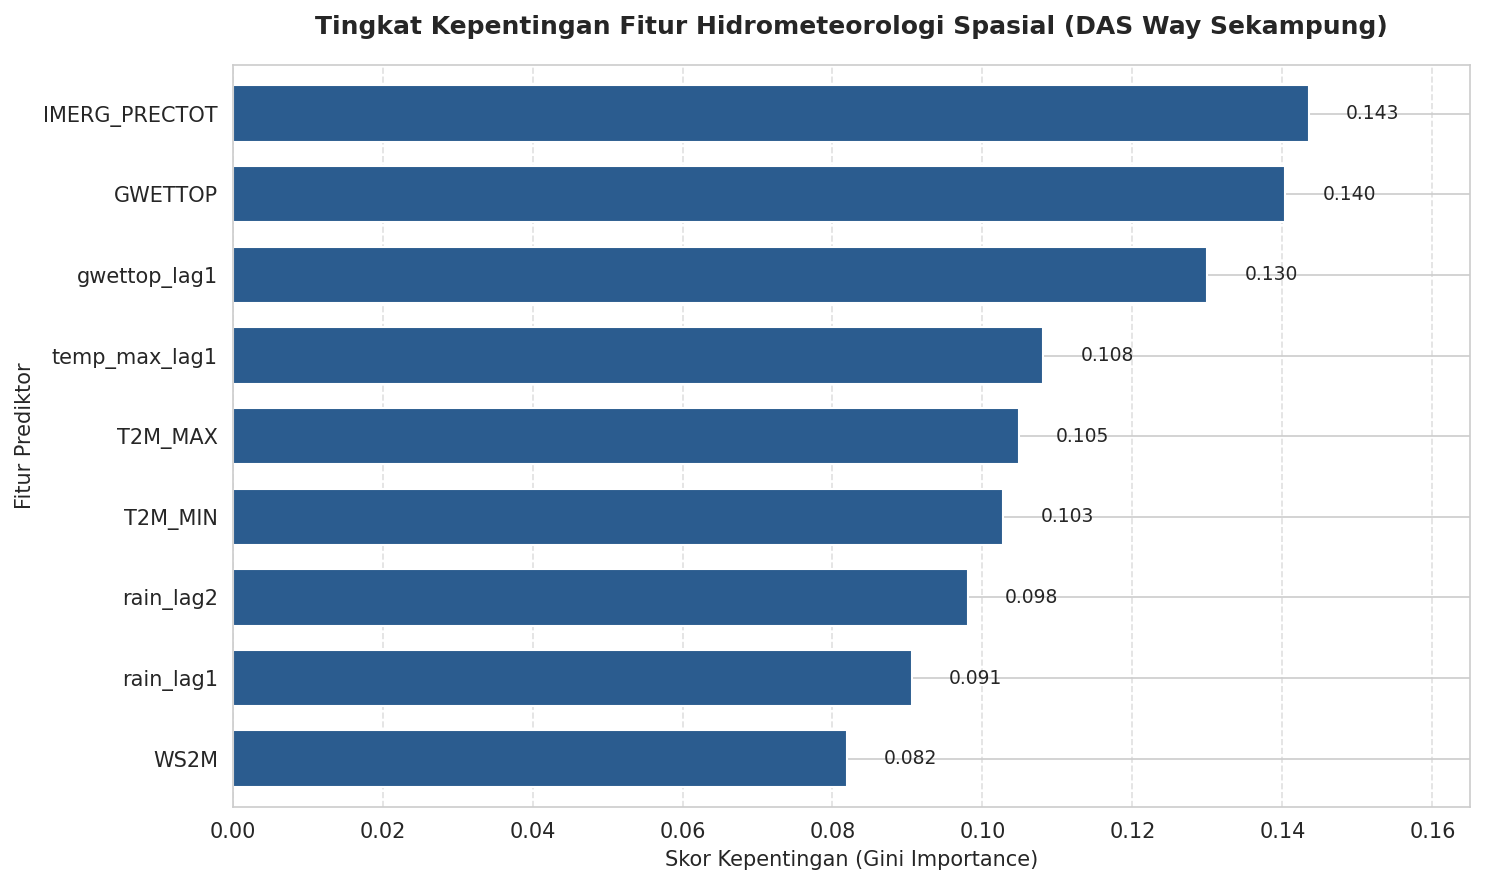

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Ambil model Random Forest yang sudah dilatih
rf_model = models["Random Forest"]

# Gunakan kolom yang sesuai dengan data latih model tersebut (X_train)
features_used = X_train.columns

# Hitung Feature Importance dan urutkan
importances = pd.Series(
    rf_model.feature_importances_, index=features_used
).sort_values(ascending=True)

# Plotting
plt.figure(figsize=(10, 6), dpi=150)
ax = importances.plot(kind="barh", color="#2b5c8f", width=0.7)

# Tambahkan label nilai di ujung bar
for index, value in enumerate(importances):
    ax.text(value + 0.005, index, f"{value:.3f}", va="center", fontsize=9)

plt.title(
    "Tingkat Kepentingan Fitur Hidrometeorologi Spasial (DAS Way Sekampung)",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Skor Kepentingan (Gini Importance)", fontsize=10)
plt.ylabel("Fitur Prediktor", fontsize=10)

# Perbaikan syntax plt.xlim (menggunakan tanda kali '*')
plt.xlim(0, max(importances) * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()

# Simpan dan tampilkan grafik
plt.savefig("feature_importance_das.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
# 1. Bentuk tabel matriks terintegrasi berdasarkan tanggal (Date Index)
df_merged = pd.DataFrame({"date": df_hulu["date"]})

# GANTI IMERG_PRECTOT DENGAN PRECTOTCORR DI SINI:
df_merged["rain_hulu"] = df_hulu["PRECTOTCORR"]
df_merged["rain_tengah"] = df_tengah["PRECTOTCORR"]
df_merged["rain_hilir"] = df_hilir["PRECTOTCORR"]

# Fitur Kejenuhan Air Tanah (Soil Wetness)
df_merged["soil_wetness_hulu"] = df_hulu["GWETTOP"]
df_merged["soil_wetness_tengah"] = df_tengah["GWETTOP"]
df_merged["soil_wetness_hilir"] = df_hilir["GWETTOP"]

# Rata-rata Suhu & Angin DAS
df_merged["temp_max_das"] = (
    df_hulu["T2M_MAX"] + df_tengah["T2M_MAX"] + df_hilir["T2M_MAX"]
) / 3
df_merged["wind_speed_das"] = (
    df_hulu["WS2M"] + df_tengah["WS2M"] + df_hilir["WS2M"]
) / 3

# 2. Spatio-Temporal Lag Features (H-1 dan H-2 dari Hulu & Tengah)
df_merged["rain_hulu_lag1"] = df_merged["rain_hulu"].shift(1)
df_merged["rain_hulu_lag2"] = df_merged["rain_hulu"].shift(2)
df_merged["rain_tengah_lag1"] = df_merged["rain_tengah"].shift(1)

# Akumulasi hujan 3 harian di DAS (Indikator banjir genangan/luapan)
df_merged["rain_das_3day_sum"] = (
    (
        df_merged["rain_hulu"]
        + df_merged["rain_tengah"]
        + df_merged["rain_hilir"]
    )
    .rolling(window=3)
    .sum()
)


# 3. Label Potensi Bahaya Banjir
def tentukan_label_risiko(row):
    if (row["rain_hilir"] >= 50 or row["rain_tengah"] >= 50) and row[
        "soil_wetness_hilir"
    ] >= 0.85:
        return "Bahaya / Luapan"
    elif (
        row["rain_das_3day_sum"] >= 80 or row["rain_hulu"] >= 50
    ) and row["soil_wetness_tengah"] >= 0.82:
        return "Waspada"
    elif row["rain_hilir"] > 10 or row["rain_tengah"] > 10:
        return "Siaga Ringan"
    else:
        return "Aman"


df_merged["flood_risk_label"] = df_merged.apply(tentukan_label_risiko, axis=1)

# Bersihkan nilai NaN akibat proses shift dan rolling (hanya akan membuang 2 baris pertama)
df_clean = df_merged.dropna().reset_index(drop=True)

print("Distribusi Kelas Potensi Bahaya Banjir DAS Way Sekampung:")
print(df_clean["flood_risk_label"].value_counts())

Distribusi Kelas Potensi Bahaya Banjir DAS Way Sekampung:
flood_risk_label
Aman               2825
Waspada             711
Siaga Ringan        441
Bahaya / Luapan      39
Name: count, dtype: int64


In [17]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point, box

# 1. Definisi Koordinat Titik Lokasi
grid_data = [
    {
        "Zona": "Hulu (Batutegi)",
        "Kode": "hulu",
        "Lat": -5.05,
        "Lon": 104.85,
        "Rata_Hujan_mm": df_clean["rain_hulu"].mean(),
        "Maks_Hujan_mm": df_clean["rain_hulu"].max(),
    },
    {
        "Zona": "Tengah (Argoguruh)",
        "Kode": "tengah",
        "Lat": -5.16,
        "Lon": 105.11,
        "Rata_Hujan_mm": df_clean["rain_tengah"].mean(),
        "Maks_Hujan_mm": df_clean["rain_tengah"].max(),
    },
    {
        "Zona": "Hilir (Sekampung Hilir)",
        "Kode": "hilir",
        "Lat": -5.45,
        "Lon": 105.60,
        "Rata_Hujan_mm": df_clean["rain_hilir"].mean(),
        "Maks_Hujan_mm": df_clean["rain_hilir"].max(),
    },
]
df_grid = pd.DataFrame(grid_data)

# 2. Buat GeoDataFrame Titik Koordinat (EPSG:4326 - WGS 84)
gdf_points = gpd.GeoDataFrame(
    df_grid,
    geometry=gpd.points_from_xy(df_grid["Lon"], df_grid["Lat"]),
    crs="EPSG:4326",
)

# 3. Buat GeoDataFrame Bounding Box Grid NASA POWER (0.5 x 0.5 derajat)
grid_boxes = [
    box(lon - 0.25, lat - 0.25, lon + 0.25, lat + 0.25)
    for lon, lat in zip(df_grid["Lon"], df_grid["Lat"])
]
gdf_boxes = gpd.GeoDataFrame(df_grid, geometry=grid_boxes, crs="EPSG:4326")

# 4. Simpan ke File Spatial GeoPackage (.gpkg)
file_output = "DAS_Way_Sekampung_NASA.gpkg"
gdf_points.to_file(file_output, layer="titik_stasiun_das", driver="GPKG")
gdf_boxes.to_file(file_output, layer="grid_nasa_power_das", driver="GPKG")

print(f"✅ Berhasil menyimpan file {file_output}")

✅ Berhasil menyimpan file DAS_Way_Sekampung_NASA.gpkg


In [18]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point, box

# 1. Definisi 9 Titik Grid NASA POWER (3 DAS x 3 Wilayah)
grid_semua_das = [
    # --- DAS WAY SEKAMPUNG ---
    {
        "DAS": "Way Sekampung",
        "Zona": "Hulu (Batutegi)",
        "Kode": "sekampung_hulu",
        "Lat": -5.05,
        "Lon": 104.85,
    },
    {
        "DAS": "Way Sekampung",
        "Zona": "Tengah (Argoguruh)",
        "Kode": "sekampung_tengah",
        "Lat": -5.16,
        "Lon": 105.11,
    },
    {
        "DAS": "Way Sekampung",
        "Zona": "Hilir (Sekampung Hilir)",
        "Kode": "sekampung_hilir",
        "Lat": -5.45,
        "Lon": 105.60,
    },
    # --- DAS WAY SEPUTIH ---
    {
        "DAS": "Way Seputih",
        "Zona": "Hulu (Sendang Agung)",
        "Kode": "seputih_hulu",
        "Lat": -4.85,
        "Lon": 104.95,
    },
    {
        "DAS": "Way Seputih",
        "Zona": "Tengah (Gunung Sugih)",
        "Kode": "seputih_tengah",
        "Lat": -4.90,
        "Lon": 105.20,
    },
    {
        "DAS": "Way Seputih",
        "Zona": "Hilir (Mataram Baru/Kuala)",
        "Kode": "seputih_hilir",
        "Lat": -4.75,
        "Lon": 105.80,
    },
    # --- DAS WAY TULANG BAWANG ---
    {
        "DAS": "Way Tulang Bawang",
        "Zona": "Hulu (Banjit/Kasui)",
        "Kode": "tulangbawang_hulu",
        "Lat": -4.50,
        "Lon": 104.60,
    },
    {
        "DAS": "Way Tulang Bawang",
        "Zona": "Tengah (Menggala)",
        "Kode": "tulangbawang_tengah",
        "Lat": -4.55,
        "Lon": 105.25,
    },
    {
        "DAS": "Way Tulang Bawang",
        "Zona": "Hilir (Rawa Jitu)",
        "Kode": "tulangbawang_hilir",
        "Lat": -4.30,
        "Lon": 105.80,
    },
]

df_semua = pd.DataFrame(grid_semua_das)

# 2. Buat GeoDataFrame Titik Koordinat (EPSG:4326 - WGS 84)
gdf_points = gpd.GeoDataFrame(
    df_semua,
    geometry=gpd.points_from_xy(df_semua["Lon"], df_semua["Lat"]),
    crs="EPSG:4326",
)

# 3. Buat GeoDataFrame Poligon Box Grid NASA POWER (0.5 x 0.5 derajat)
grid_boxes = [
    box(lon - 0.25, lat - 0.25, lon + 0.25, lat + 0.25)
    for lon, lat in zip(df_semua["Lon"], df_semua["Lat"])
]
gdf_boxes = gpd.GeoDataFrame(df_semua, geometry=grid_boxes, crs="EPSG:4326")

# 4. Simpan Seluruh DAS ke dalam Satu File GeoPackage (.gpkg)
file_output = "Seluruh_DAS_Lampung_NASA.gpkg"
gdf_points.to_file(file_output, layer="titik_stasiun_3das", driver="GPKG")
gdf_boxes.to_file(file_output, layer="grid_nasa_power_3das", driver="GPKG")

print(f"✅ Berhasil mengekspor 3 DAS ke {file_output}")

✅ Berhasil mengekspor 3 DAS ke Seluruh_DAS_Lampung_NASA.gpkg


In [19]:
import os
import pandas as pd
import requests

# 1. Definisi Koordinat 3 Titik DAS Way Sekampung
titik_sekampung = {
    "hulu_batutegi": {"lat": -5.05, "lon": 104.85, "nama": "Hulu (Batutegi)"},
    "tengah_argoguruh": {
        "lat": -5.16,
        "lon": 105.11,
        "nama": "Tengah (Argoguruh)",
    },
    "hilir_sekampung_hilir": {
        "lat": -5.45,
        "lon": 105.60,
        "nama": "Hilir (Sekampung Hilir)",
    },
}

# 2. Parameter Tanggal (Sesuaikan dengan kebutuhan analisis kamu)
START_DATE = "20100101"  # Format: YYYYMMDD (1 Jan 2010)
END_DATE = "20231231"  # Format: YYYYMMDD (31 Des 2023)

# Folder tempat menyimpan hasil download
output_dir = "data_nasa_sekampung"
os.makedirs(output_dir, exist_ok=True)

# 3. Looping Download Data per Titik
list_df = []

for kode, info in titik_sekampung.items():
    print(f"📥 Mengunduh data untuk: {info['nama']} ({kode})...")

    # API NASA POWER untuk Data Harian (Daily)
    url = (
        f"https://power.larc.nasa.gov/api/temporal/daily/point?"
        f"parameters=PRECTOTCORR,T2M,RH2M,WS2M&community=AG&"
        f"longitude={info['lon']}&latitude={info['lat']}&"
        f"start={START_DATE}&end={END_DATE}&format=JSON"
    )

    response = requests.get(url)

    if response.status_code == 200:
        data = response.json()["properties"]["parameter"]

        # Buat DataFrame dari hasil API
        df_temp = pd.DataFrame(data)
        df_temp.index.name = "Tanggal"
        df_temp = df_temp.reset_index()

        # Tambahkan kolom identitas titik
        df_temp["Kode_Titik"] = kode
        df_temp["Nama_Zona"] = info["nama"]
        df_temp["Latitude"] = info["lat"]
        df_temp["Longitude"] = info["lon"]

        # Rename kolom sesuai variabel cuaca
        df_temp = df_temp.rename(
            columns={
                "PRECTOTCORR": "Curah_Hujan_mm",
                "T2M": "Suhu_Rata2_C",
                "RH2M": "Kelembapan_pct",
                "WS2M": "Kecepatan_Angin_ms",
            }
        )

        # Ubah format tanggal ke YYYY-MM-DD
        df_temp["Tanggal"] = pd.to_datetime(
            df_temp["Tanggal"], format="%Y%m%d"
        )

        # Simpan file CSV per titik individu
        file_titik = os.path.join(output_dir, f"nasa_power_{kode}.csv")
        df_temp.to_csv(file_titik, index=False)
        print(f"   ✅ Berhasil disimpan ke: {file_titik}")

        list_df.append(df_temp)
    else:
        print(f"   ❌ Gagal mengunduh data {kode}. Status: {response.status_code}")

# 4. Gabungkan Semua Titik Menjadi 1 File CSV Utama
df_gabungan = pd.concat(list_df, ignore_index=True)
file_gabungan = os.path.join(
    output_dir, "NASA_POWER_Way_Sekampung_Gabungan.csv"
)
df_gabungan.to_csv(file_gabungan, index=False)

print("\n🎉 SEMUA PROSES SELESAI!")
print(f"📁 File gabungan tersimpan di: {file_gabungan}")

📥 Mengunduh data untuk: Hulu (Batutegi) (hulu_batutegi)...
   ✅ Berhasil disimpan ke: data_nasa_sekampung/nasa_power_hulu_batutegi.csv
📥 Mengunduh data untuk: Tengah (Argoguruh) (tengah_argoguruh)...
   ✅ Berhasil disimpan ke: data_nasa_sekampung/nasa_power_tengah_argoguruh.csv
📥 Mengunduh data untuk: Hilir (Sekampung Hilir) (hilir_sekampung_hilir)...
   ✅ Berhasil disimpan ke: data_nasa_sekampung/nasa_power_hilir_sekampung_hilir.csv

🎉 SEMUA PROSES SELESAI!
📁 File gabungan tersimpan di: data_nasa_sekampung/NASA_POWER_Way_Sekampung_Gabungan.csv
